# 1. Import Libraries


In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Regression Models
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

# Tree Visualization
from sklearn.tree import plot_tree

# Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## 2. Load Dataset

In [2]:
df = pd.read_csv("boston_data.csv")

df.head()


,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,5,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
4,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9


In [4]:
df.shape

(333, 12)

### 3. Define Features and Target

In [5]:
df = df.drop(columns=["ID"])

In [6]:
X = df.drop("medv", axis=1)

y = df["medv"]

In [7]:
print(X.shape)

print(y.shape)

(333, 10)
(333,)


#### Observation
All predictor variables are stored in X.

Target variable (house prices) is stored in y.

### 4. Train Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [9]:
print(X_train.shape)

print(X_test.shape)

(266, 10)
(67, 10)


#### Observation
80% of the data has been used for training.

20% of the data has been reserved for testing.

#### 5. Decision Tree Regressor

In [10]:
dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


### Prediction

In [11]:
dt_pred = dt_model.predict(X_test)

#### Evaluation

In [12]:
print(
    "MAE:",
    mean_absolute_error(
        y_test,
        dt_pred
    )
)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            dt_pred
        )
    )
)

print(
    "R2:",
    r2_score(
        y_test,
        dt_pred
    )
)

MAE: 3.4432835820895527
RMSE: 5.411499640414749
R2: 0.6746127266364579


### 6. KNN Regressor

In [13]:
knn_model = KNeighborsRegressor(
    n_neighbors=5
)

knn_model.fit(
    X_train,
    y_train
)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### Prediction

In [14]:
knn_pred = knn_model.predict(
    X_test
)

In [15]:
print(
    "MAE:",
    mean_absolute_error(
        y_test,
        knn_pred
    )
)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            knn_pred
        )
    )
)

print(
    "R2:",
    r2_score(
        y_test,
        knn_pred
    )
)

MAE: 4.468955223880596
RMSE: 7.2796518696489585
R2: 0.4111746261918916


## 7. Random Forest Regressor

In [16]:
rf_model = RandomForestRegressor(
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [17]:
rf_pred = rf_model.predict(
    X_test
)

In [18]:
print(
    "MAE:",
    mean_absolute_error(
        y_test,
        rf_pred
    )
)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            rf_pred
        )
    )
)

print(
    "R2:",
    r2_score(
        y_test,
        rf_pred
    )
)

MAE: 2.207089552238806
RMSE: 2.980972988006413
R2: 0.9012626706467386


### 8. Model Comparison

In [20]:
results = {

    "Decision Tree": [

        mean_absolute_error(
            y_test,
            dt_pred
        ),

        np.sqrt(
            mean_squared_error(
                y_test,
                dt_pred
            )
        ),

        r2_score(
            y_test,
            dt_pred
        )
    ],

    "KNN": [

        mean_absolute_error(
            y_test,
            knn_pred
        ),

        np.sqrt(
            mean_squared_error(
                y_test,
                knn_pred
            )
        ),

        r2_score(
            y_test,
            knn_pred
        )
    ],

    "Random Forest": [

        mean_absolute_error(
            y_test,
            rf_pred
        ),

        np.sqrt(
            mean_squared_error(
                y_test,
                rf_pred
            )
        ),

        r2_score(
            y_test,
            rf_pred
        )
    ]
}

In [21]:
comparison = pd.DataFrame(
    results,
    index=["MAE", "RMSE", "R2"]
).T

comparison

,MAE,RMSE,R2
Decision Tree,3.443284,5.411500,0.674613
KNN,4.468955,7.279652,0.411175
Random Forest,2.207090,2.980973,0.901263


#### 9. Hyperparameter Tuning

In [22]:
param_grid = {

    "n_estimators":
    [50,100,200],

    "max_depth":
    [3,5,10,None]
}

In [23]:
grid_search = GridSearchCV(

    estimator=RandomForestRegressor(
        random_state=42
    ),

    param_grid=param_grid,

    cv=5,

    scoring="r2"
)

In [24]:
grid_search.fit(
    X_train,
    y_train
)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


#### Best Parameters

In [ ]:
print(
    grid_search.best_params_
)

#### 10. Best Model Evaluation

In [27]:
best_model = grid_search.best_estimator_

best_pred = best_model.predict(
    X_test
)

In [28]:
print(
    "MAE:",
    mean_absolute_error(
        y_test,
        best_pred
    )
)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            best_pred
        )
    )
)

print(
    "R2:",
    r2_score(
        y_test,
        best_pred
    )
)

MAE: 2.2215375564031183
RMSE: 3.0504753888623197
R2: 0.8966048075808406


#### 11. Feature Importance


In [29]:
importance = pd.Series(

    best_model.feature_importances_,

    index=X.columns

).sort_values(
    ascending=False
)

importance


lstat      0.417074
rm         0.402556
dis        0.087530
age        0.020713
nox        0.018677
tax        0.015767
ptratio    0.013695
rad        0.011923
indus      0.009871
chas       0.002193
dtype: float64

#### Visualization

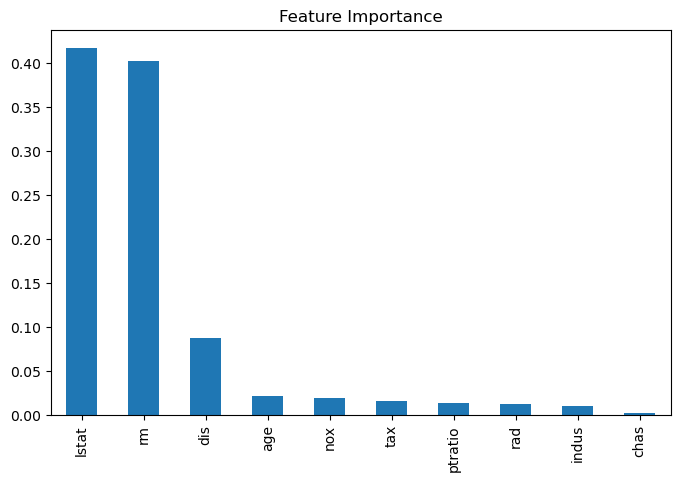

In [30]:
plt.figure(figsize=(8,5))

importance.plot(
    kind="bar"
)

plt.title(
    "Feature Importance"
)

plt.show()

### Conclusion

- Decision Tree, KNN and Random Forest models were trained.

- Model performance was evaluated using MAE, RMSE and R² Score.

- Random Forest achieved the best performance.

- Hyperparameter tuning further improved model quality.

- Feature importance analysis showed that RM, LSTAT and NOX are among the most influential variables for predicting house prices.

## Model Save Karo

In [32]:
import joblib

joblib.dump(best_model, "boston_model.pkl")

['boston_model.pkl']